<a href="https://colab.research.google.com/github/JariusF10-8/bt4222/blob/main/notebooks/eda/final_report_section_1_2_data_distributions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 1.2 Data distributions and feature-usage implications

This notebook reproduces two figures from verified **saved repository outputs**, then optionally recomputes distributions from your actual shared **train/validation** files. It does not train a model, change a feature bundle, or read test data.

**Run in Colab:** edit the next cell before running; allow Drive access; check paths; run top to bottom. No repository ZIP, raw TSVs or GPU is needed. Required packages are NumPy, pandas and Matplotlib (normally supplied by Colab).

The generated timestamped folder contains PNG/SVG figures, CSV summaries, the two-column report table and input provenance. A live run adds category/subcategory, hourly/date and article-confidence plots. If shared data are unavailable, set `RUN_SHARED_DATA_ANALYSIS=False` to reproduce only the embedded evidence.

All observed counts have explicit denominators. Cold IDs mean IDs absent from train event users / complete train candidate article IDs, not the separate never-updated-embedding safeguard.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# EDIT THESE SETTINGS BEFORE RUNNING THIS CELL.
RUN_SHARED_DATA_ANALYSIS = IN_COLAB  # Set True locally when the folders are available.
MOUNT_GOOGLE_DRIVE = True
STORAGE_ROOT = Path('/content/drive/MyDrive/BT4222 Group Project') if IN_COLAB else Path.cwd()
PROCESSED_VERSION = 'v2'
FEATURE_VERSION = 'unified_v1'
CANDIDATE_CHUNK_SIZE = 100_000
SCREENING_AUDIT_CSV = None  # Optional: Path('.../feature_mlp/<run>/feature_table.csv').
RUN_NAME = 'section12_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')

if IN_COLAB and RUN_SHARED_DATA_ANALYSIS and MOUNT_GOOGLE_DRIVE:
    if not Path('/content/drive/MyDrive').is_dir():
        drive.mount('/content/drive')

PROCESSED_DIR = STORAGE_ROOT / 'data/processed' / PROCESSED_VERSION
FEATURE_DIR = STORAGE_ROOT / 'outputs/features' / FEATURE_VERSION
OUTPUT_DIR = ((STORAGE_ROOT / 'figures/section1_2') if RUN_SHARED_DATA_ANALYSIS
              else (Path.cwd() / 'section1_2_previews')) / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print('Preprocessing:', PROCESSED_DIR)
print('Feature bundle:', FEATURE_DIR)
print('Figures and tables:', OUTPUT_DIR)
print('Read actual shared data:', RUN_SHARED_DATA_ANALYSIS)


Mounted at /content/drive
Preprocessing: /content/drive/MyDrive/BT4222 Group Project/data/processed/v2
Feature bundle: /content/drive/MyDrive/BT4222 Group Project/outputs/features/unified_v1
Figures and tables: /content/drive/MyDrive/BT4222 Group Project/figures/section1_2/section12_20261108_100954_493253
Read actual shared data: True


## 1 Reproduce the checked repository evidence

The numbers below are copied programmatically from committed notebook output tables, with their source blobs and cell IDs recorded. No individual histories, timestamps or confidence values have been invented to draw these figures.

The attention run is saved under local `v1/unified_local`; the unified notebook reports the shared `v2/unified_v1` handoff. Their partition totals match, but that alone does not establish byte-for-byte equivalence. The live section is the way to confirm figures against the bundle used for your final experiments.


In [2]:
SNAPSHOT = {'commit': 'b902e928b0551c83600b97eeab37f227c13a9b1e', 'source_type': 'committed saved notebook outputs; not a fresh full-data execution', 'cold_shares_precision': 'fractions printed to four decimal places by the model notebook', 'history_over50_precision': 'one decimal percentage printed by model notebook', 'summary': [{'partition': 'train', 'events': 95071, 'candidates': 3389342, 'articles': 43370, 'empty_histories': 1735, 'articles_without_uniform_vector': 5999, 'training_dates': 4}, {'partition': 'validation', 'events': 61894, 'candidates': 2454102, 'articles': 38421, 'empty_histories': 1503, 'articles_without_uniform_vector': 5605, 'training_dates': 2}], 'cold': {'cold_user_exposure_share': 0.2443, 'cold_item_exposure_share': 0.5034}, 'history_counts': {'history_0': 1503, 'history_1_9': 16565, 'history_10_29': 21063, 'history_30_49': 10097, 'history_50_plus': 12666}, 'history_over50_pct': 19.9, 'rare': {'pairs': 276, 'rare_pairs': 107, 'rare_articles': 192}, 'screening': [{'group': 'article entity statistics', 'drop': 14, 'keep': 20, 'All': 34}, {'group': 'article text & category flags', 'drop': 3, 'keep': 4, 'All': 7}, {'group': 'category match', 'drop': 0, 'keep': 3, 'All': 3}, {'group': 'entity match', 'drop': 1, 'keep': 9, 'All': 10}, {'group': 'history profile', 'drop': 11, 'keep': 20, 'All': 31}, {'group': 'impression context', 'drop': 0, 'keep': 4, 'All': 4}, {'group': 'time x category', 'drop': 8, 'keep': 30, 'All': 38}, {'group': 'All', 'drop': 37, 'keep': 90, 'All': 127}], 'sources': [{'key': 'unified', 'path': 'notebooks/features/Unified_Feature_Engineering.ipynb', 'sha': 'e3b56fecd82765a0ab8da90e7594c11eedcace0b', 'url': 'https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/features/Unified_Feature_Engineering.ipynb'}, {'key': 'attention', 'path': 'notebooks/models/Candidate_Attention_MLP.ipynb', 'sha': 'd8f1d82a6d2f830dcc8b20400061cf1fa0912915', 'url': 'https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/Candidate_Attention_MLP.ipynb'}, {'key': 'feature_mlp', 'path': 'notebooks/models/feature-based_MLP.ipynb', 'sha': '3230314e147f3b1bf4bccffd8a6f37375a61ed9e', 'url': 'https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/feature-based_MLP.ipynb'}, {'key': 'cbf', 'path': 'notebooks/models/CBF.ipynb', 'sha': 'ab35815d7c9b20eea5b5796ef5e0bbd5ced89031', 'url': 'https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/CBF.ipynb'}, {'key': 'ubcf', 'path': 'notebooks/models/UBCF.ipynb', 'sha': 'c1125d9a0f4441978cbe1e8e620346c3bb42d124', 'url': 'https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/UBCF.ipynb'}, {'key': 'neumf', 'path': 'notebooks/models/NeuMF.ipynb', 'sha': 'c80954f1f7c3296d132bffca1d48d369487aa8cf', 'url': 'https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/NeuMF.ipynb'}, {'key': 'categorical_eda', 'path': 'notebooks/eda/Categorical_Text_Features.ipynb', 'sha': 'b54cb59048acc6840a9c72114d9d264828c94de4', 'url': 'https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/eda/Categorical_Text_Features.ipynb'}, {'key': 'chris', 'path': 'notebooks/features/feature_engineering_chris.ipynb', 'sha': 'd7cb0ee451339470aa18e82b039e351946b9ce87', 'url': 'https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/features/feature_engineering_chris.ipynb'}], 'evidence_cells': {'coverage': 'Unified_Feature_Engineering.ipynb: unified-026', 'cold_and_history': 'Candidate_Attention_MLP.ipynb: 9565648d', 'rare_subcategories': 'feature_engineering_chris.ipynb: 3f282139', 'screening': 'feature-based_MLP.ipynb: code cell 9'}, 'screening_rules': {'dominant_value_share_above': 0.999, 'absolute_pearson_above': 0.95, 'fit': 'training only; candidate level uses up to 300000 sampled rows'}, 'scope_note': 'Saved attention results use local v1/unified_local; unified outputs use the shared v2/unified_v1 bundle. Counts agree, but exact file equivalence requires manifest/file hashes.'}
SNAPSHOT_SUMMARY = pd.DataFrame(SNAPSHOT["summary"])
SNAPSHOT_SCREENING = pd.DataFrame(SNAPSHOT["screening"])


In [3]:
from pathlib import Path
import json, hashlib, math, textwrap
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator

BLUE, ORANGE, TEAL, GREY = '#28658C', '#D98332', '#32877F', '#687685'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12,
                     'axes.titlesize': 13, 'axes.labelsize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'svg.fonttype': 'none', 'savefig.facecolor': 'white'})

def require(condition, message):
    if not condition:
        raise ValueError(message)

def hash_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def save_figure(fig, folder, name, footer):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    footer='\n'.join(textwrap.fill(line,width=125) for line in footer.splitlines())
    fig.text(.02, .012, footer, fontsize=8.2, color=GREY, va='bottom')
    fig.savefig(folder / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(folder / f'{name}.svg', bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return folder / f'{name}.png'

def plot_validation_distributions(cold, history_counts, history_over50_pct, folder, basis):
    counts = pd.Series(history_counts, dtype='int64')
    require(counts.sum() > 0, 'No validation impressions')
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
    fig.subplots_adjust(left=.10, right=.98, bottom=.22, top=.84, wspace=.40)
    ax = axes[0]
    values = [100 * cold['cold_user_exposure_share'], 100 * cold['cold_item_exposure_share']]
    bars = ax.barh(['Unseen user ID', 'Unseen article ID'], values, color=[BLUE, ORANGE], height=.48)
    ax.set_xlim(0, max(65, min(100, max(values)*1.2 + 5)))
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.set_xlabel('Validation candidate exposures')
    ax.set_title('A  Cold-start exposure shares', loc='left', pad=16)
    for bar, value in zip(bars, values):
        inside=value>90
        ax.text(value-1 if inside else value+1, bar.get_y()+bar.get_height()/2,
                f'{value:.1f}%', va='center', ha='right' if inside else 'left',
                color='white' if inside else 'black', fontsize=12)
    ax = axes[1]
    labels = ['0', '1–9', '10–29', '30–49', '≥50']
    shares = 100 * counts.to_numpy() / counts.sum()
    bars = ax.bar(labels, shares, color=[ORANGE, BLUE, BLUE, BLUE, TEAL], width=.65)
    ax.set_ylim(0, max(shares) * 1.24)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.set_ylabel('Validation impressions')
    ax.set_xlabel('Supplied history length (articles)')
    ax.set_title('B  History-length distribution', loc='left', pad=16)
    for bar, value in zip(bars, shares):
        ax.text(bar.get_x()+bar.get_width()/2, value+.5, f'{value:.1f}%', ha='center', fontsize=10.5)
    ax.text(.98, .95, f'{history_over50_pct:.1f}% exceed 50', transform=ax.transAxes,
            ha='right', va='top', fontsize=10, color=GREY)
    return save_figure(fig, folder, 'validation_cold_start_and_history',
        basis + '\nCold-start denominator: candidate exposures; history denominator: impressions. ID vocabularies use training only.')

def plot_entity_and_screening(summary, screening, folder, basis):
    summary = summary.loc[summary['partition'].isin(['train','validation'])].copy()
    screening = screening.loc[screening['group'].ne('All')].copy()
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8), gridspec_kw={'width_ratios':[.9,1.4]})
    fig.subplots_adjust(left=.09, right=.98, bottom=.22, top=.83, wspace=.90)
    ax=axes[0]
    pct=100*summary['articles_without_uniform_vector']/summary['articles']
    bars=ax.bar(['Train','Validation'],pct,color=[BLUE,ORANGE],width=.56)
    ax.set_ylim(0,max(20,min(100,float(pct.max())*1.25)))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.set_ylabel('Articles in each partition news table')
    ax.set_title('A  No usable entity vector',loc='left',pad=16)
    for bar,value,row in zip(bars,pct,summary.itertuples()):
        ax.text(bar.get_x()+bar.get_width()/2,value-1 if value>90 else value+.4,
                f'{value:.2f}%',ha='center',va='top' if value>90 else 'bottom',
                color='white' if value>90 else 'black',fontsize=11)
        ax.text(bar.get_x()+bar.get_width()/2,1.0,f'{row.articles_without_uniform_vector:,}\n/ {row.articles:,}',
                ha='center',va='bottom',fontsize=10,color='white')
    ax=axes[1]
    names={'article entity statistics':'Article entity statistics',
           'article text & category flags':'Article text/category flags',
           'category match':'Category matching','entity match':'Entity matching',
           'history profile':'History profile','impression context':'Impression context',
           'time x category':'Time × category'}
    labels=[names.get(x,x) for x in screening['group']]
    y=np.arange(len(labels))
    ax.barh(y,screening['keep'],color=TEAL,label='Kept')
    ax.barh(y,screening['drop'],left=screening['keep'],color='#D7DFE5',label='Removed')
    ax.set_yticks(y,labels,fontsize=10.5)
    ax.invert_yaxis()
    ax.set_xlim(0,max(screening['All'])*1.22)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel('Offered numerical columns')
    ax.set_title('B  Feature-based MLP screening',loc='left',pad=16)
    for i,row in enumerate(screening.itertuples()):
        ax.text(row.All+.6,i,f'{row.keep}/{row.All}',va='center',fontsize=10)
    ax.legend(loc='lower right',bbox_to_anchor=(1.04,-.34),ncol=2,frameon=False,fontsize=10)
    return save_figure(fig,folder,'entity_coverage_and_feature_screening',
        basis + '\nEntity-vector denominator: partition articles (candidates and history). Screening is a saved training-only model result, not all 185 dictionary entries.')

def build_report_table(summary,cold,over50,rare,screening):
    s=summary.set_index('partition')
    v=s.loc['validation']
    clean=screening.loc[screening['group'].ne('All')]
    kept,total=int(clean['keep'].sum()),int(clean['All'].sum())
    rows=[
      (f"{100*cold['cold_user_exposure_share']:.1f}% of validation candidate exposures involve unseen users; "
       f"{100*cold['cold_item_exposure_share']:.1f}% involve unseen articles, relative to training ID vocabularies.",
       'Use content/history models alongside ID-only NeuMF; retain explicit unknown-ID fallbacks.'),
      (f"{100*v.empty_histories/v.events:.1f}% of validation impressions have empty supplied histories.",
       'Provide empty-history fallbacks, padding masks and history-availability signals.'),
      (f'{over50:.1f}% of validation impressions have more than 50 history clicks.',
       'State the coverage/compute trade-off of the neural models’ most-recent-50 history cap; assess alternatives on validation.'),
      (f'{rare["rare_pairs"]} of {rare["pairs"]} training category/subcategory pairs have fewer than 5 articles '
       f'({rare["rare_articles"]} articles in total).',
       'Use parent-aware rare-subcategory buckets and preserve the parent category.'),
      (f"{100*v.articles_without_uniform_vector/v.articles:.2f}% of validation articles lack a usable uniform entity vector.",
       'Retain zero-vector fallbacks and missing-vector flags; combine entity information with text/categories.'),
      (f'{int(s.loc["train","training_dates"])} training dates provide no repeated weekly cycle.',
       'Use daily hour sine/cosine; keep weekday/weekend predictors exploratory.'),
      (f'The feature-based MLP retains {kept} of {total} offered numerical columns after training-only screening.',
       'Screen near-constant and highly correlated columns; distinguish available bundle features from selected model inputs.')]
    return pd.DataFrame(rows,columns=['Observed finding','Supported feature or modelling decision'])

def to_markdown_table(frame):
    def escape(v): return str(v).replace('|','\\|').replace('\n',' ')
    head='| '+' | '.join(map(escape,frame.columns))+' |\n'
    line='| '+' | '.join(['---']*len(frame.columns))+' |\n'
    return head+line+'\n'.join('| '+' | '.join(escape(v) for v in row)+' |' for row in frame.itertuples(index=False,name=None))+'\n'



In [4]:
snapshot_table = build_report_table(SNAPSHOT_SUMMARY, SNAPSHOT['cold'], SNAPSHOT['history_over50_pct'],
                                    SNAPSHOT['rare'], SNAPSHOT_SCREENING)
display(snapshot_table)
snapshot_table.to_csv(OUTPUT_DIR / 'snapshot_report_table.csv', index=False)
(OUTPUT_DIR / 'snapshot_report_table.md').write_text(to_markdown_table(snapshot_table))
(OUTPUT_DIR / 'evidence_snapshot.json').write_text(json.dumps(SNAPSHOT, indent=2) + '\n')


,Observed finding,Supported feature or modelling decision
0,24.4% of validation candidate exposures involv...,Use content/history models alongside ID-only N...
1,2.4% of validation impressions have empty supp...,"Provide empty-history fallbacks, padding masks..."
2,19.9% of validation impressions have more than...,State the coverage/compute trade-off of the ne...
3,107 of 276 training category/subcategory pairs...,Use parent-aware rare-subcategory buckets and ...
4,14.59% of validation articles lack a usable un...,Retain zero-vector fallbacks and missing-vecto...
5,4 training dates provide no repeated weekly cy...,Use daily hour sine/cosine; keep weekday/weeke...
6,The feature-based MLP retains 90 of 127 offere...,Screen near-constant and highly correlated col...


4980

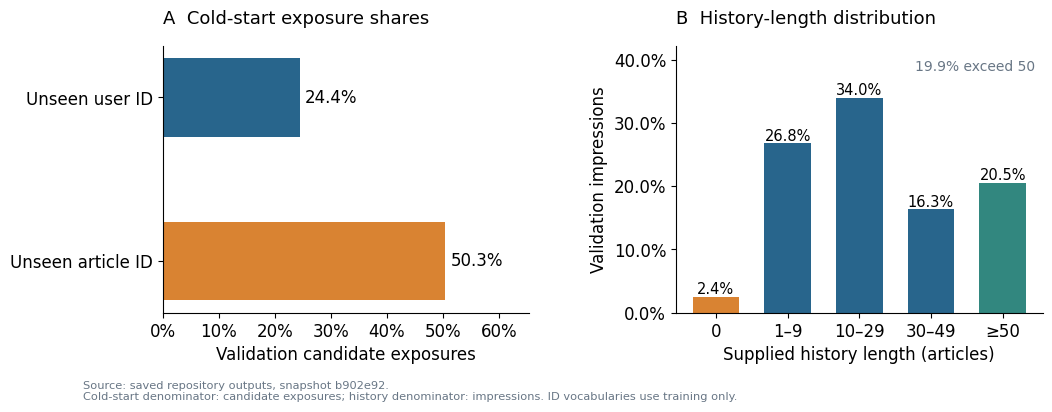

PosixPath('/content/drive/MyDrive/BT4222 Group Project/figures/section1_2/section12_20261108_100954_493253/validation_cold_start_and_history.png')

In [5]:
plot_validation_distributions(SNAPSHOT['cold'], SNAPSHOT['history_counts'], SNAPSHOT['history_over50_pct'],
                              OUTPUT_DIR, 'Source: saved repository outputs, snapshot ' + SNAPSHOT['commit'][:7] + '.')


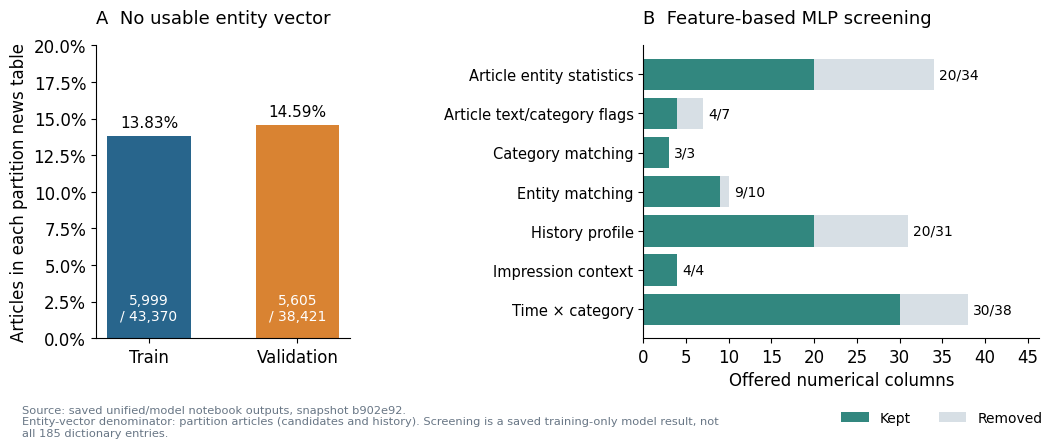

PosixPath('/content/drive/MyDrive/BT4222 Group Project/figures/section1_2/section12_20261108_100954_493253/entity_coverage_and_feature_screening.png')

In [6]:
plot_entity_and_screening(SNAPSHOT_SUMMARY, SNAPSHOT_SCREENING, OUTPUT_DIR,
                          'Source: saved unified/model notebook outputs, snapshot ' + SNAPSHOT['commit'][:7] + '.')


## 2 Recompute from the actual shared files

Only preprocessing `train/validation/events.csv` and `candidates.csv`, feature `train/validation/news_features.csv`, and the two manifests are required. Candidate rows are streamed in chunks. Validation **labels are not requested**; train labels supply a descriptive click-rate calculation only. The feature manifest must match the preprocessing manifest.

Definitions: history distributions count **impressions**; cold-user/article shares count **candidate exposures**; entity coverage counts **partition articles**, including history references. Rare-subcategory counts use **training parent/subcategory pairs** with fewer than five metadata-present articles.


In [7]:
def bool_flag(values,name):
    x=pd.Series(values).astype(str).str.strip().str.lower()
    require(x.isin(['0','1','false','true','0.0','1.0']).all(),f'Invalid flag: {name}')
    return x.isin(['1','true','1.0']).to_numpy()

def profile_shared_data(processed_dir,feature_dir,chunk_size=100_000):
    """Read train/validation only; validation labels are never requested."""
    processed_dir,feature_dir=Path(processed_dir),Path(feature_dir)
    pm=processed_dir/'manifest.json';fm=feature_dir/'manifest.json'
    require(pm.is_file() and fm.is_file(),'Both complete preprocessing and feature folders need manifest.json')
    pmeta=json.loads(pm.read_text());fmeta=json.loads(fm.read_text())
    require({'train','validation'}.issubset(pmeta.get('partitions',[])),'Train and validation are required')
    require(fmeta.get('source_manifest_sha256')==hash_file(pm),'Feature/preprocessing manifests do not match')
    inputs=[]
    events={};articles={};counts={};train_items=set();train_clicks=0;train_rows=0
    for part in ['train','validation']:
        ep=processed_dir/part/'events.csv'
        e=pd.read_csv(ep,usecols=['event_key','user_id','timestamp','history_length'],dtype={'event_key':'string','user_id':'string'})
        e['timestamp']=pd.to_datetime(e['timestamp'],errors='raise')
        h=pd.to_numeric(e['history_length'],errors='raise').to_numpy()
        require(np.isfinite(h).all() and (h>=0).all() and (h==np.floor(h)).all(),'Invalid history length')
        e['history_length']=h.astype('int64')
        require(e['event_key'].is_unique and len(e)>0,'Empty/duplicate event keys')
        require(e['user_id'].notna().all(),'Missing user ID')
        ap=feature_dir/part/'news_features.csv'
        available=pd.read_csv(ap,nrows=0).columns
        needed=['news_id','category','subcategory','metadata_missing','entity_vector_missing_uniform']
        require(set(needed).issubset(available),'Article feature schema lacks required profiling columns')
        optional=[c for c in ['entity_conf_mean','entity_conf_missing','num_embedded_entities','has_entity_at_title_start'] if c in available]
        a=pd.read_csv(ap,usecols=needed+optional,dtype={'news_id':'string','category':'string','subcategory':'string'},keep_default_na=False)
        require(a['news_id'].is_unique,'Repeated article ID')
        a['metadata_missing']=bool_flag(a['metadata_missing'],'metadata_missing')
        a['entity_vector_missing_uniform']=bool_flag(a['entity_vector_missing_uniform'],'entity_vector_missing_uniform')
        if 'entity_conf_missing' in a:
            a['entity_conf_missing']=bool_flag(a['entity_conf_missing'],'entity_conf_missing')
        events[part],articles[part]=e,a
        for path in [ep,ap]:inputs.append({'path':str(path),'bytes':path.stat().st_size})
    require(events['train']['timestamp'].max()<events['validation']['timestamp'].min(),'Temporal partitions overlap')
    train_users=set(events['train']['user_id'])
    unknown_user=unknown_item=validation_rows=0
    for part in ['train','validation']:
        e=events[part]
        index=pd.Index(e['event_key'])
        per_event=np.zeros(len(e),dtype='int64')
        cold_users=~e['user_id'].isin(train_users).to_numpy()
        path=processed_dir/part/'candidates.csv'
        cols=['event_key','news_id']+(['label'] if part=='train' else [])
        for chunk in pd.read_csv(path,usecols=cols,dtype={'event_key':'string','news_id':'string'},chunksize=chunk_size,keep_default_na=False):
            pos=index.get_indexer(chunk['event_key'])
            require((pos>=0).all(),'Candidate refers to unknown event')
            require(chunk['news_id'].isin(articles[part]['news_id']).all(),'Candidate lacks article metadata')
            per_event+=np.bincount(pos,minlength=len(e))
            if part=='train':
                require(chunk['label'].isin([0,1]).all(),'Nonbinary training label')
                train_items.update(chunk['news_id'].unique())
                train_clicks+=int(chunk['label'].sum());train_rows+=len(chunk)
            else:
                validation_rows+=len(chunk)
                unknown_user+=int(cold_users[pos].sum())
                unknown_item+=int((~chunk['news_id'].isin(train_items)).sum())
        require((per_event>0).all(),'An event has no candidate rows')
        counts[part]=per_event
        inputs.append({'path':str(path),'bytes':path.stat().st_size,'label_column_read':part=='train'})
    result=[]
    for part in ['train','validation']:
        e,a=events[part],articles[part]
        result.append({'partition':part,'events':len(e),'candidates':int(counts[part].sum()),'articles':len(a),
                       'empty_histories':int(e['history_length'].eq(0).sum()),
                       'articles_without_uniform_vector':int(a['entity_vector_missing_uniform'].sum()),
                       'training_dates':int(e['timestamp'].dt.normalize().nunique())})
    summary=pd.DataFrame(result)
    h=events['validation']['history_length']
    bins=pd.cut(h,[-1,0,9,29,49,np.inf],labels=['history_0','history_1_9','history_10_29','history_30_49','history_50_plus'])
    history_counts=bins.value_counts(sort=False).to_dict()
    known=articles['train'].loc[~articles['train']['metadata_missing']]
    pairs=known.groupby(['category','subcategory'],dropna=False).size()
    rare={'pairs':len(pairs),'rare_pairs':int(pairs.lt(5).sum()),'rare_articles':int(pairs[pairs.lt(5)].sum())}
    cold={'cold_user_exposure_share':unknown_user/validation_rows,'cold_item_exposure_share':unknown_item/validation_rows}
    provenance={'mode':'recomputed from provided shared files','created_at_utc':datetime.now(timezone.utc).isoformat(),
                'processed_manifest_sha256':hash_file(pm),'feature_manifest_sha256':hash_file(fm),
                'processed_directory':str(processed_dir),'feature_directory':str(feature_dir),
                'partitions_read':['train','validation'],'label_columns_read_from':['train'],
                'inputs':inputs,'cold_id_reference':'train event users and complete train candidate article IDs',
                'history_denominator':'impressions','entity_denominator':'partition news table articles, including history references'}
    return {'summary':summary,'cold':cold,'history_counts':history_counts,
            'history_over50_pct':100*float(h.gt(50).mean()),'rare':rare,'events':events,'articles':articles,
            'candidate_counts':counts,'training_clicks':train_clicks,'training_candidates':train_rows,'provenance':provenance}

def additional_live_plots(profile,folder):
    """New analyses are plotted only after genuine data have been loaded."""
    out=Path(folder)
    train=profile['articles']['train']
    known=train.loc[~train['metadata_missing']]
    cats=known['category'].value_counts()
    pairs=known.groupby(['category','subcategory'],dropna=False).size()
    fig,axes=plt.subplots(1,2,figsize=(10,4.4))
    fig.subplots_adjust(left=.13,right=.98,bottom=.25,top=.85,wspace=.45)
    top=cats.head(10).sort_values()
    axes[0].barh(top.index,100*top/len(known),color=BLUE)
    axes[0].set_xlabel('Training articles with metadata (%)')
    axes[0].set_title('A  Top 10 categories',loc='left')
    binned=pd.cut(pairs,[0,1,4,9,49,199,np.inf],labels=['1','2–4','5–9','10–49','50–199','200+']).value_counts(sort=False)
    axes[1].bar(binned.index,binned.values,color=[ORANGE,ORANGE,BLUE,BLUE,BLUE,BLUE])
    axes[1].set_xlabel('Articles per parent/subcategory pair')
    axes[1].set_ylabel('Category/subcategory pairs')
    axes[1].tick_params(axis='x',rotation=30)
    axes[1].set_title('B  Subcategory frequency',loc='left')
    save_figure(fig,out,'live_category_and_subcategory_distributions',
                'Computed from training news_features.csv only. Orange bins contain fewer than 5 articles per pair.')
    cats.rename('articles').to_csv(out/'live_training_category_counts.csv')
    pairs.rename('articles').to_csv(out/'live_training_subcategory_counts.csv')

    fig,axes=plt.subplots(1,2,figsize=(10,4.3))
    fig.subplots_adjust(left=.09,right=.98,bottom=.22,top=.85,wspace=.35)
    for part,color in [('train',BLUE),('validation',ORANGE)]:
        stamps=profile['events'][part]['timestamp']
        rates=stamps.dt.hour.value_counts().reindex(range(24),fill_value=0)/len(stamps)*100
        axes[0].plot(rates.index,rates,marker='o',markersize=3,label=part.title(),color=color)
    axes[0].set(xlabel='Recorded impression hour',ylabel='Impressions within partition (%)',xticks=[0,6,12,18,23])
    axes[0].set_title('A  Hourly activity',loc='left')
    axes[0].legend(frameon=False,fontsize=10)
    dates=profile['events']['train']['timestamp'].dt.normalize().value_counts().sort_index()
    axes[1].bar(dates.index.strftime('%a\n%d %b'),dates.values,color=BLUE)
    axes[1].set_ylabel('Training impressions')
    axes[1].set_title('B  Training date coverage',loc='left')
    save_figure(fig,out,'live_hour_and_date_distributions',
                'Recorded timestamps retain the dataset timezone assumption (unspecified). Activity counts alone do not establish time-dependent preferences.')

    if {'entity_conf_mean','entity_conf_missing'}.issubset(train.columns):
        valid=train.loc[~train['entity_conf_missing'],'entity_conf_mean'].astype(float)
        require(valid.between(0,1).all(),'Entity confidence lies outside [0,1]')
        fig,ax=plt.subplots(figsize=(6.8,3.7))
        fig.subplots_adjust(left=.13,right=.98,bottom=.24,top=.83)
        ax.hist(valid,bins=np.linspace(0,1,26),color=TEAL,edgecolor='white')
        ax.set(xlabel='Article mean linking confidence (embedded entities)',ylabel='Training articles',xlim=(0,1))
        ax.set_title('Entity-confidence distribution',loc='left')
        save_figure(fig,out,'live_entity_confidence_distribution',
                    'One observation per article with a defined confidence summary; missing fallbacks excluded. This is not click probability.')
        valid.describe(percentiles=[.01,.1,.5,.9,.99]).to_csv(out/'live_entity_confidence_summary.csv')

    rate=100*profile['training_clicks']/profile['training_candidates']
    pd.DataFrame([{'basis':'complete original training candidates','click_share_pct':rate},
                  {'basis':'1 click + 4 sampled non-clicks','click_share_pct':20.}]).to_csv(out/'live_training_click_balance.csv',index=False)
    profile['summary'].to_csv(out/'live_partition_summary.csv',index=False)
    pd.DataFrame([profile['cold']]).to_csv(out/'live_validation_cold_exposure_shares.csv',index=False)
    pd.Series(profile['history_counts'],name='impressions').to_csv(out/'live_validation_history_bins.csv')
    dates.rename('impressions').to_csv(out/'live_training_date_counts.csv')
    rows=[]
    for part,e in profile['events'].items():
        rows.extend({'partition':part,'hour':int(h),'impressions':int(n)} for h,n in e['timestamp'].dt.hour.value_counts().sort_index().items())
    pd.DataFrame(rows).to_csv(out/'live_hour_counts.csv',index=False)
    (out/'live_input_provenance.json').write_text(json.dumps(profile['provenance'],indent=2)+'\n')


In [8]:
LIVE = None
if RUN_SHARED_DATA_ANALYSIS:
    LIVE = profile_shared_data(PROCESSED_DIR, FEATURE_DIR, CANDIDATE_CHUNK_SIZE)
    display(LIVE['summary'])
    print('Cold validation exposure shares:', LIVE['cold'])
    print('Training rare-subcategory summary:', LIVE['rare'])
    print('Validation histories longer than 50:', round(LIVE['history_over50_pct'], 2), '%')
else:
    print('Shared-data analysis disabled. Only snapshot-derived evidence was reproduced.')


,partition,events,candidates,articles,empty_histories,articles_without_uniform_vector,training_dates
0,train,95071,3389342,43370,1735,5999,4
1,validation,61894,2454102,38421,1503,5605,2


Cold validation exposure shares: {'cold_user_exposure_share': 0.24426979807685256, 'cold_item_exposure_share': 0.5033979842728623}
Training rare-subcategory summary: {'pairs': 276, 'rare_pairs': 107, 'rare_articles': 192}
Validation histories longer than 50: 19.94 %


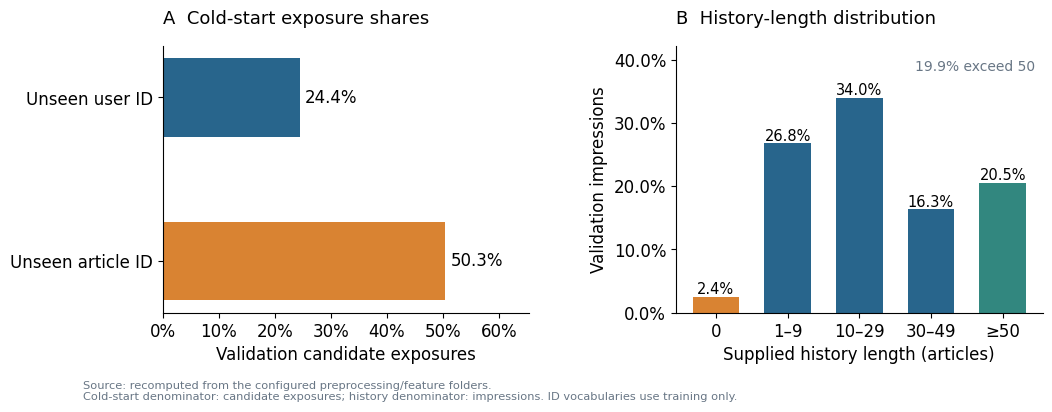

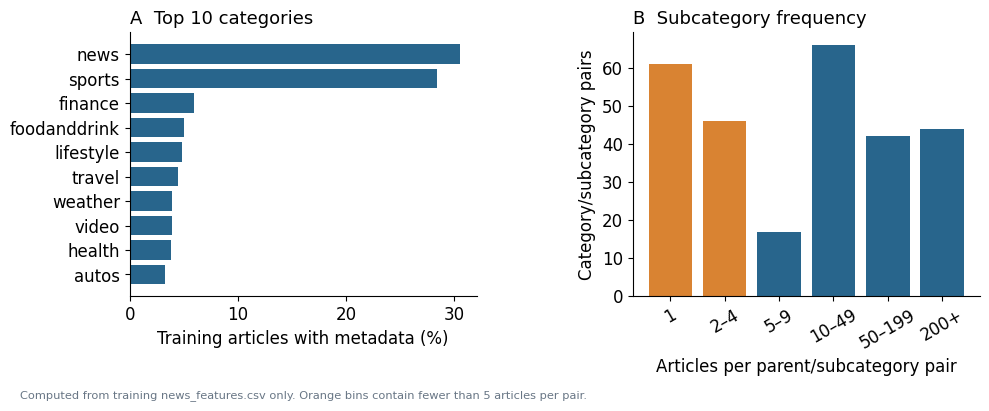

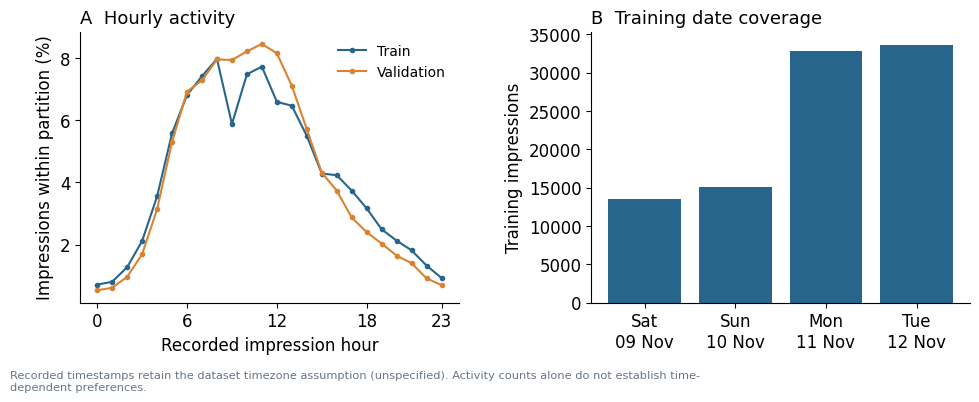

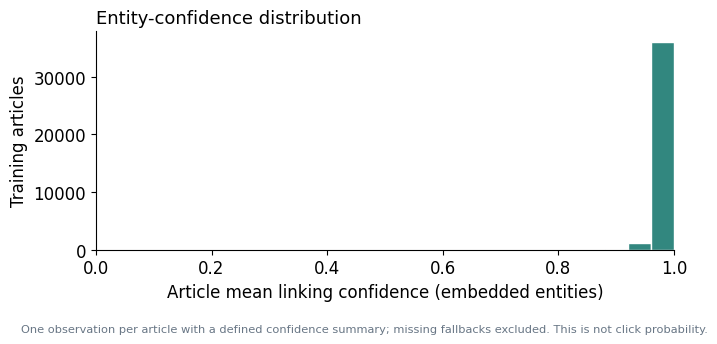

In [9]:
if LIVE is not None:
    live_dir = OUTPUT_DIR / 'recomputed_from_shared_data'
    live_dir.mkdir(exist_ok=False)
    plot_validation_distributions(LIVE['cold'], LIVE['history_counts'], LIVE['history_over50_pct'], live_dir,
                                  'Source: recomputed from the configured preprocessing/feature folders.')
    additional_live_plots(LIVE, live_dir)


## 3 Attach an actual model screening audit when available

`feature_table.csv` is generated by the feature-based MLP and records training-only dominance/correlation decisions. It is stronger evidence than inferring usefulness from a feature name. Point `SCREENING_AUDIT_CSV` to the audit from the exact model run reported in the final report.

When it is omitted, the screening row below deliberately remains the **saved repository model result** (127 offered, 90 retained). It is not recomputed from your Drive data, and should not be presented as a new screening result for another run.


Screening evidence: saved model notebook output; not recomputed here


,Observed finding,Supported feature or modelling decision
0,24.4% of validation candidate exposures involv...,Use content/history models alongside ID-only N...
1,2.4% of validation impressions have empty supp...,"Provide empty-history fallbacks, padding masks..."
2,19.9% of validation impressions have more than...,State the coverage/compute trade-off of the ne...
3,107 of 276 training category/subcategory pairs...,Use parent-aware rare-subcategory buckets and ...
4,14.59% of validation articles lack a usable un...,Retain zero-vector fallbacks and missing-vecto...
5,4 training dates provide no repeated weekly cy...,Use daily hour sine/cosine; keep weekday/weeke...
6,The feature-based MLP retains 90 of 127 offere...,Screen near-constant and highly correlated col...


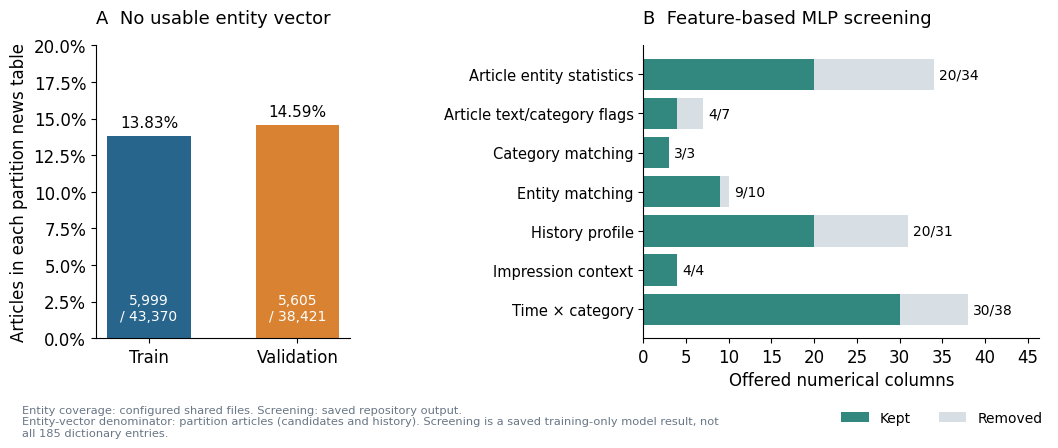

In [10]:
screening = SNAPSHOT_SCREENING.copy()
screening_basis = 'saved model notebook output; not recomputed here'
if SCREENING_AUDIT_CSV is not None:
    audit = pd.read_csv(Path(SCREENING_AUDIT_CSV))
    require({'group', 'decision', 'feature'}.issubset(audit), 'Unexpected feature_table.csv schema')
    require(audit['decision'].eq('keep').any(), 'No kept model features in audit')
    audit['kept'] = audit['decision'].eq('keep')
    audit['removed'] = audit['decision'].str.startswith('drop:')
    require((audit['kept'] | audit['removed']).all(), 'Unknown audit decision')
    screening = audit.groupby('group', sort=False).agg(keep=('kept', 'sum'), drop=('removed', 'sum'), All=('feature', 'size')).reset_index()
    screening_basis = str(Path(SCREENING_AUDIT_CSV))
print('Screening evidence:', screening_basis)
if LIVE is not None:
    final_table = build_report_table(LIVE['summary'], LIVE['cold'], LIVE['history_over50_pct'], LIVE['rare'], screening)
    display(final_table)
    final_table.to_csv(live_dir / 'section_1_2_report_table.csv', index=False)
    (live_dir / 'section_1_2_report_table.md').write_text(to_markdown_table(final_table))
    plot_entity_and_screening(LIVE['summary'], screening, live_dir,
                             'Entity coverage: configured shared files. Screening: ' + ('specified model audit.' if SCREENING_AUDIT_CSV else 'saved repository output.'))
    (live_dir / 'screening_evidence.json').write_text(json.dumps({'basis': screening_basis}, indent=2))


## 4 What to report and what to verify

Use the **recomputed** table and figures when they differ from the embedded outputs. A short Section 1.2 can use the first cold-start/history figure and 5–7 rows linking data findings to implemented choices. Category counts justify rare buckets; confidence histograms describe annotation reliability; hourly counts describe activity, not proof of category preference changes.

Detailed permutation importance, with/without-feature comparisons and CTR freshness experiments belong in Section 3. A correlation-based removal rule does not prove a feature is useless, and the history-length distribution does not prove 50 is the best cap.

The source feature-based MLP uses a 99.9% dominant-value threshold and |Pearson r| > 0.95 (up to 300,000 sampled training candidate rows). Do not describe highly correlated columns as literally identical. The source model transforms heavily skewed nonnegative columns with `log1p`, then applies training-fitted scaling.

**Model-specific inputs:** ID-only NeuMF and UBCF do not consume the engineered bundle; CBF fits text features from preprocessing; the feature-based MLP uses uniform entity/text/category representations and 90 screened numerical inputs in the saved run; candidate attention uses 44 compact numerical inputs, with the 20 historical CTR columns tested separately. The new nightly/mixed CTR modes are not inputs to the selected candidate-attention run.

**Comparison checks:** the current feature-based MLP refits on train + validation, while candidate attention keeps a train-fitted model. State/align this before comparing test results. Its `Findings` prose also differs from its saved current training/test output tables; reconcile it before quoting scores. Neither issue changes the coverage counts plotted here.

The categorical EDA notebook provides useful code for category/article-vs-exposure shares, vocabulary novelty and entity position, but has no committed execution outputs at this snapshot. This notebook adds live category, confidence and time analyses instead of assigning unverified values to them.


## Source snapshot

Commit: `b902e928b0551c83600b97eeab37f227c13a9b1e`.

- [notebooks/features/Unified_Feature_Engineering.ipynb](https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/features/Unified_Feature_Engineering.ipynb)
- [notebooks/models/Candidate_Attention_MLP.ipynb](https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/Candidate_Attention_MLP.ipynb)
- [notebooks/models/feature-based_MLP.ipynb](https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/feature-based_MLP.ipynb)
- [notebooks/models/CBF.ipynb](https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/CBF.ipynb)
- [notebooks/models/UBCF.ipynb](https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/UBCF.ipynb)
- [notebooks/models/NeuMF.ipynb](https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/models/NeuMF.ipynb)
- [notebooks/eda/Categorical_Text_Features.ipynb](https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/eda/Categorical_Text_Features.ipynb)
- [notebooks/features/feature_engineering_chris.ipynb](https://github.com/JariusF10-8/bt4222/blob/b902e928b0551c83600b97eeab37f227c13a9b1e/notebooks/features/feature_engineering_chris.ipynb)